# 04 — Modèle 2 : ResNet18 pré-entraîné (transfer learning)

**Objectif :** faire mieux que le baseline (`03_model1_baseline.ipynb`) sur le **même** split de test
(split par série, voir notebook 02).

## Rappel du baseline (modèle 1)
Sur le test : accuracy ≈ 73 %, F1 macro ≈ 0,53, rappel **Stone ≈ 21 %** et **Tumor ≈ 4 %**. Les problèmes identifiés :
1. **Sur-apprentissage massif** : 100 % en train, loss de validation qui monte dès l'epoch 2.
2. **Biais vers Normal et Cyst** : les tumeurs et les calculs sont classés Normal.
3. **Mauvaise généralisation à de nouveaux examens** : des séries entières sont ratées.
4. **Choix du meilleur modèle sur l'accuracy**, une métrique trompeuse avec des classes déséquilibrées.

## Ce qu'on change, et pourquoi

| Problème du baseline | Changement dans le modèle 2 |
|---|---|
| Peu d'examens différents : le CNN from scratch mémorise | **ResNet18 pré-entraîné sur ImageNet** (`src/model2.py`) : il part de filtres génériques (bords, textures) au lieu de tout apprendre sur ~140 séries |
| Lésions de quelques pixels à 128 px | Résolution **224 px** |
| Sur-apprentissage | **Augmentation forte** sur GPU (`src/augment.py`) : rotation ±15°, zoom 0,85–1,15, translation, contraste/luminosité, bruit ; **label smoothing** 0,1 ; **early stopping** |
| Meilleur modèle choisi sur l'accuracy | Choix sur le **F1 macro** de validation (chaque classe compte autant) |
| Fine-tuning de poids pré-entraînés | **learning rate plus faible** (3e-4 au lieu de 1e-3) |

On garde le reste à l'identique pour que la comparaison soit honnête : même split, loss pondérée par classe,
AdamW + OneCycleLR, calcul en fp32 (le fp16 produit des NaN sur GTX 16xx).

In [1]:
import os, sys
from pathlib import Path

# Le notebook tourne depuis notebooks/ : on se place à la racine du projet
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from PIL import Image

from src import get_model
from src.augment import strong_augment
from src.data import CLASSES, DATA_DIR, list_split_files, load_split
from src.viz import setup_style, plot_curves, plot_confusion, collect_runs, read_run, SERIES, SPLIT_COLORS
from train import train
from eval import evaluate, predict

setup_style()
CONFIG = "configs/model2.yaml"
print("GPU :", torch.cuda.get_device_name(0))

GPU : NVIDIA GeForce GTX 1650


## 1. Configuration
Par rapport à `configs/model1.yaml` : nouvelles clés `data.augment`, `train.label_smoothing`, `train.select_metric` et `train.patience` (gérées par `train.py`).

In [2]:
cfg = yaml.safe_load(Path(CONFIG).read_text())
print(yaml.safe_dump(cfg, sort_keys=False))

model:
  name: model2
  params:
    pretrained: true
    dropout: 0.3
data:
  img_size: 224
  augment: strong
train:
  epochs: 15
  batch_size: 32
  lr: 0.0003
  weight_decay: 0.0001
  class_weights: true
  label_smoothing: 0.1
  select_metric: f1_macro
  patience: 5
seed: 42



## 2. Architecture

ResNet18 de torchvision, poids ImageNet. Deux adaptations :
- **entrée** : nos images ont 1 canal dans [-1, 1]. On les ramène dans [0, 1], on duplique le canal en 3 (RGB)
  et on applique la normalisation ImageNet, que le réseau a vue pendant son pré-entraînement ;
- **sortie** : la couche finale (1000 classes ImageNet) est remplacée par `Dropout(0.3) → Linear(512, 4)`.

Tout le réseau est ré-entraîné (fine-tuning complet).

In [3]:
model = get_model(cfg["model"]["name"], n_classes=len(CLASSES), **cfg["model"].get("params", {}))
bb = model.backbone
blocks = [("stem (conv1+bn1)", [bb.conv1, bb.bn1]), ("layer1", [bb.layer1]), ("layer2", [bb.layer2]),
          ("layer3", [bb.layer3]), ("layer4", [bb.layer4]), ("fc (tête)", [bb.fc])]
table = pd.DataFrame([{"bloc": n, "paramètres": sum(p.numel() for m in ms for p in m.parameters())} for n, ms in blocks]).set_index("bloc")
print(f"Total : {table['paramètres'].sum():,} paramètres (modèle 1 : 389 348, soit ~29x plus)")
table

Total : 11,178,564 paramètres (modèle 1 : 389 348, soit ~29x plus)


,paramètres
bloc,
stem (conv1+bn1),9536
layer1,147968
layer2,525568
layer3,2099712
layer4,8393728
fc (tête),2052


## 3. Données
Mêmes splits que le modèle 1, prétraités en **224 px** (le cache `data/cache/*_224.npz` est créé au premier appel, environ 3 minutes).

In [4]:
for s in ["train", "valid", "test"]:
    X, y = load_split(s, cfg["data"]["img_size"])
    print(f"{s:5s}: {X.shape}  " + "  ".join(f"{c}={n}" for c, n in zip(CLASSES, np.bincount(y))))

train: (8166, 224, 224)  Cyst=2259  Normal=3443  Stone=938  Tumor=1526


valid: (1788, 224, 224)  Cyst=512  Normal=686  Stone=197  Tumor=393
test : (1975, 224, 224)  Cyst=513  Normal=873  Stone=225  Tumor=364


### Augmentation
Chaque image du train est transformée différemment à chaque epoch. Colonne 1 : image d'origine ; colonnes suivantes : tirages aléatoires.

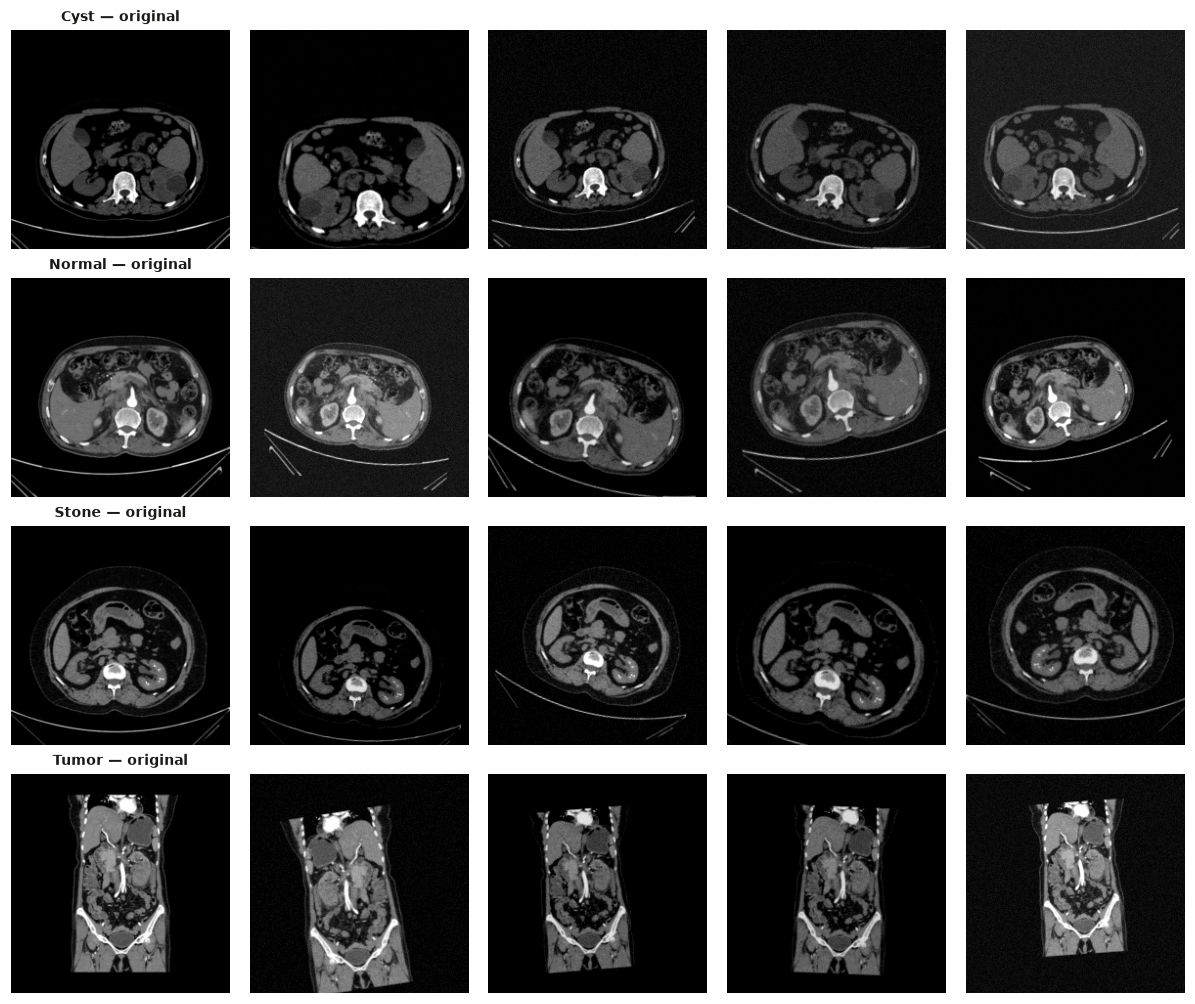

In [5]:
X_tr, y_tr = load_split("train", cfg["data"]["img_size"])
torch.manual_seed(0)
idx = [int(np.where(y_tr == k)[0][len(np.where(y_tr == k)[0]) // 2]) for k in range(len(CLASSES))]
x = torch.from_numpy(X_tr[idx]).unsqueeze(1).cuda().float() / 255
fig, axes = plt.subplots(len(idx), 5, figsize=(11, 2.3 * len(idx)))
for r in range(len(idx)):
    axes[r, 0].imshow(x[r, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    axes[r, 0].set_title(f"{CLASSES[y_tr[idx[r]]]} — original", fontsize=9)
    for c in range(1, 5):
        axes[r, c].imshow(strong_augment(x[r:r + 1].clone())[0, 0].cpu(), cmap="gray", vmin=0, vmax=1)
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Entraînement

`train()` crée un nouveau dossier `results/model2-vN/` à chaque appel (environ 50 s par epoch sur une GTX 1650).
L'entraînement s'arrête plus tôt si le F1 macro de validation ne progresse plus pendant `patience` epochs.
Pour **recharger un run existant sans réentraîner**, mettre son chemin dans `RUN_DIR`.

In [6]:
RUN_DIR = None   # ex. "results/model2-v1" pour recharger un run sans réentraîner

run_dir = Path(RUN_DIR) if RUN_DIR else train(CONFIG)
print("Run :", run_dir)

Run : results/model2-v1  |  GPU : NVIDIA GeForce GTX 1650


Paramètres : 11,178,564


Epoch  1/15 | train loss 0.9232 acc 0.7325 | val loss 0.9679 acc 0.6874 f1 0.6746 | 92.1s


Epoch  2/15 | train loss 0.5369 acc 0.9633 | val loss 1.0347 acc 0.7422 f1 0.7182 | 61.6s


Epoch  3/15 | train loss 0.4901 acc 0.9869 | val loss 0.8615 acc 0.7796 f1 0.7528 | 61.5s


Epoch  4/15 | train loss 0.4818 acc 0.9859 | val loss 0.8567 acc 0.8093 f1 0.7952 | 61.5s


... (8 outputs left out)

Epoch 13/15 | train loss 0.4253 acc 1.0000 | val loss 0.6518 acc 0.8954 f1 0.8814 | 61.8s


Epoch 14/15 | train loss 0.4247 acc 1.0000 | val loss 0.6778 acc 0.8781 f1 0.8664 | 61.8s


Epoch 15/15 | train loss 0.4246 acc 1.0000 | val loss 0.6919 acc 0.8753 f1 0.8619 | 62.0s


Meilleur val f1_macro : 0.8814 (epoch 13)
Run : results/model2-v1


## 5. Courbes d'apprentissage

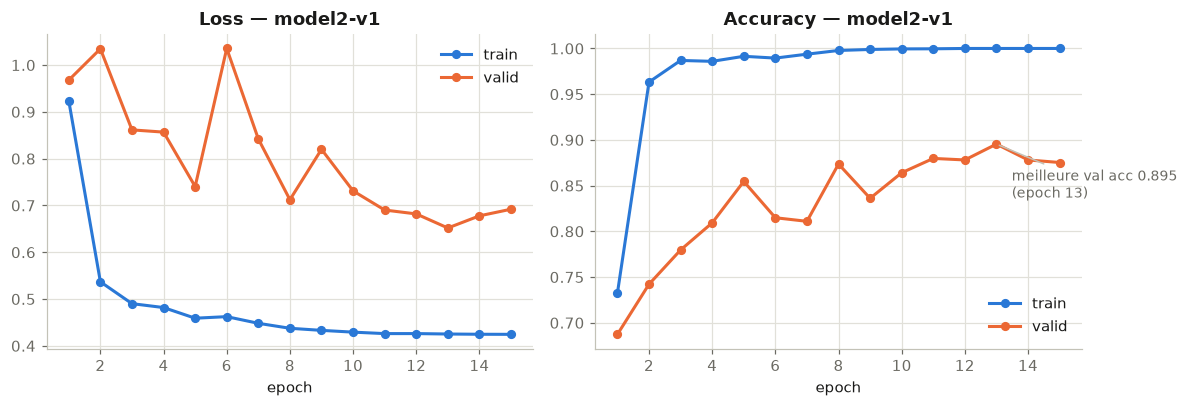

In [7]:
plot_curves(run_dir); plt.show()

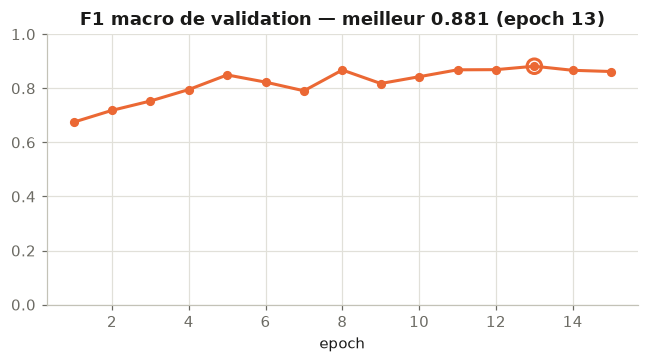

In [8]:
# F1 macro de validation : c'est la métrique qui sélectionne le meilleur modèle
_, va = read_run(run_dir)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(va.epoch, va.f1_macro, marker="o", color=SPLIT_COLORS["valid"])
best = va.loc[va.f1_macro.idxmax()]
ax.scatter([best.epoch], [best.f1_macro], s=90, facecolors="none", edgecolors=SPLIT_COLORS["valid"], lw=2)
ax.set_title(f"F1 macro de validation — meilleur {best.f1_macro:.3f} (epoch {int(best.epoch)})")
ax.set_xlabel("epoch"); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

## 6. Évaluation sur le test
Le meilleur modèle (meilleur F1 macro de validation) est évalué sur le split test, résultat dans `test_output.json`.

In [9]:
out = evaluate(run_dir)

=== TEST — model2-v1 (best.pt) ===
              precision    recall  f1-score   support

        Cyst     0.9645    0.5302    0.6843       513
      Normal     0.7954    0.9885    0.8815       873
       Stone     0.5000    0.9556    0.6565       225
       Tumor     0.8146    0.3984    0.5351       364

    accuracy                         0.7570      1975
   macro avg     0.7686    0.7182    0.6893      1975
weighted avg     0.8092    0.7570    0.7408      1975

Matrice de confusion (lignes = vrai, colonnes = prédit) :
[[272   6 202  33]
 [  0 863  10   0]
 [ 10   0 215   0]
 [  0 216   3 145]]
-> results/model2-v1/test_output.json


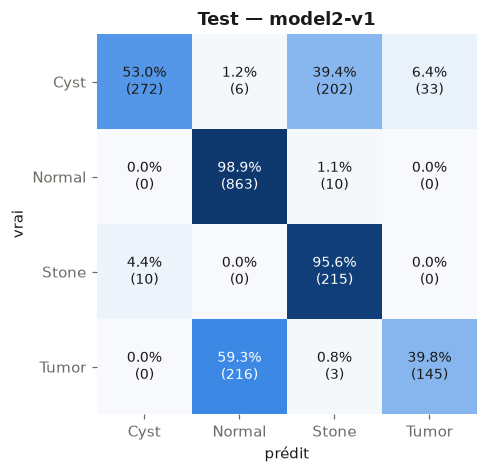

,precision,recall,f1-score,support
Cyst,0.965,0.530,0.684,513.0
Normal,0.795,0.989,0.882,873.0
Stone,0.500,0.956,0.656,225.0
Tumor,0.815,0.398,0.535,364.0


In [10]:
plot_confusion(out["confusion_matrix"]["matrix"], CLASSES, f"Test — {run_dir.name}"); plt.show()
pd.DataFrame(out["per_class"]).T.round(3)

## 7. Comparaison avec le baseline
On compare avec le dernier run évalué du modèle 1 (même split de test).

,accuracy,f1_macro,recall_Cyst,recall_Normal,recall_Stone,recall_Tumor
run,,,,,,
model1-v3,0.783,0.640,0.99,0.977,0.760,0.038
model2-v1,0.757,0.689,0.53,0.989,0.956,0.398


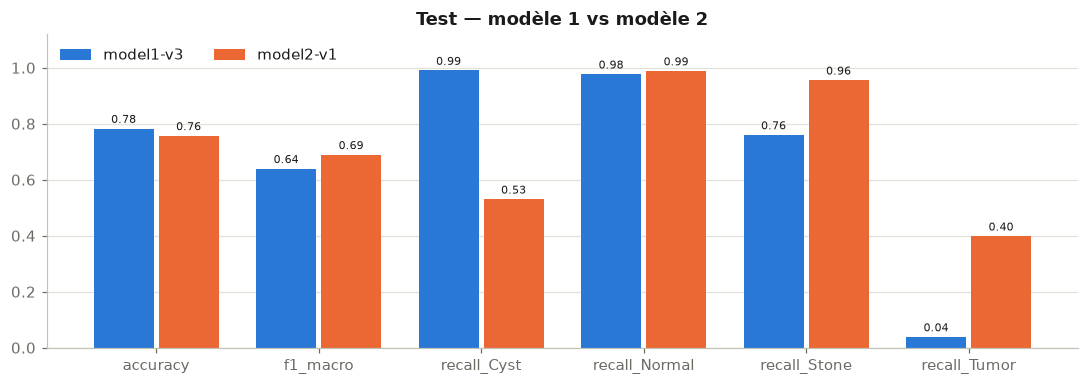

In [11]:
runs = collect_runs()
m1 = sorted([r for r in runs.index if r.startswith("model1-")], key=lambda r: int(r.split("-v")[1]))
compare = runs.loc[[m1[-1], run_dir.name]] if m1 else runs.loc[[run_dir.name]]
display(compare.round(3))

metrics = list(compare.columns)
fig, ax = plt.subplots(figsize=(10, 3.6))
w = 0.8 / len(compare)
for k, r in enumerate(compare.index):
    x = [i + (k - (len(compare) - 1) / 2) * w for i in range(len(metrics))]
    bars = ax.bar(x, compare.loc[r, metrics], w - 0.03, color=SERIES[k], label=r)
    ax.bar_label(bars, [f"{v:.2f}" for v in compare.loc[r, metrics]], fontsize=7, padding=2)
ax.set_xticks(range(len(metrics)), metrics); ax.set_ylim(0, 1.12); ax.legend(ncols=2)
ax.set_title("Test — modèle 1 vs modèle 2"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 8. Analyse des erreurs
### Performance par type de coupe

In [12]:
y, p, probs = predict(run_dir)
files = list_split_files("test")
meta = pd.read_csv(DATA_DIR / "metadata.csv").set_index(["cls", "filename"])
res = pd.DataFrame({
    "filename": [f.name for f, _ in files], "cls": [CLASSES[l] for _, l in files],
    "pred": [CLASSES[i] for i in p], "conf": probs.max(1), "correct": y == p,
})
res = res.join(meta[["view", "series"]], on=["cls", "filename"])
res.pivot_table(index="cls", columns="view", values="correct", aggfunc="mean").reindex(CLASSES).round(3)

view,axial,coronal
cls,,
Cyst,0.503,0.804
Normal,0.998,0.980
Stone,0.978,0.867
Tumor,0.211,0.843


### Erreurs regroupées par série
Une série mal classée en entier signale un examen « difficile » ; des erreurs isolées sont plutôt du bruit.

In [13]:
by_series = res.groupby("series").agg(cls=("cls", "first"), view=("view", "first"),
                                        n=("correct", "size"), accuracy=("correct", "mean"))
print(f"Séries de test entièrement correctes : {(by_series.accuracy == 1).sum()} / {len(by_series)}")
print(f"Séries de test entièrement ratées    : {(by_series.accuracy == 0).sum()} / {len(by_series)}")
by_series.sort_values("accuracy").head(10).round(3)

Séries de test entièrement correctes : 33 / 46
Séries de test entièrement ratées    : 4 / 46


,cls,view,n,accuracy
series,,,,
Cyst_0011,Cyst,coronal,9,0.000
Cyst_0035,Cyst,axial,191,0.000
Tumor_0203,Tumor,axial,202,0.000
Stone_0177,Stone,coronal,6,0.000
Stone_0176,Stone,axial,6,0.500
Cyst_0019,Cyst,axial,14,0.714
Cyst_0056,Cyst,axial,117,0.718
Tumor_0208,Tumor,coronal,24,0.750
Tumor_0206,Tumor,coronal,54,0.796


### Exemples d'erreurs (les plus confiantes)

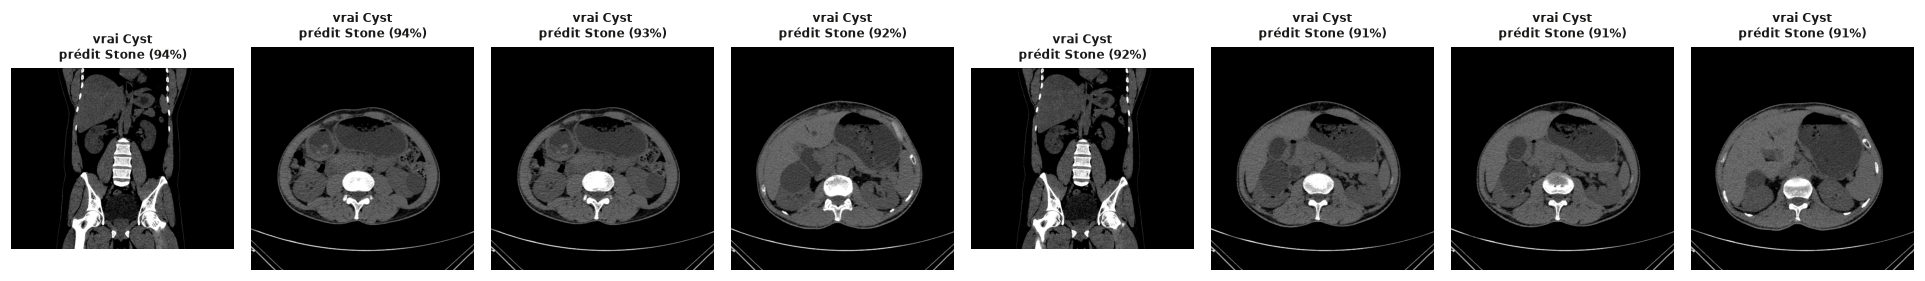

In [14]:
errors = res[~res.correct].sort_values("conf", ascending=False).head(8)
if len(errors):
    fig, axes = plt.subplots(1, len(errors), figsize=(2.2 * len(errors), 2.8), squeeze=False)
    for ax, (_, r) in zip(axes[0], errors.iterrows()):
        ax.imshow(Image.open(DATA_DIR / "test" / r.cls / r.filename).convert("L"), cmap="gray"); ax.axis("off")
        ax.set_title(f"vrai {r.cls}\nprédit {r.pred} ({r.conf:.0%})", fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("Aucune erreur sur le test.")

## 9. Conclusions

Run `model2-v1`, split par série. Les chiffres varient d'un run à l'autre (voir plus bas).

**Résultats test**

| | accuracy | F1 macro | rappel Cyst | rappel Normal | rappel Stone | rappel Tumor |
|---|---|---|---|---|---|---|
| modèle 1 (`model1-v1` / `model1-v3`, même config) | 0,73 / 0,78 | 0,53 / 0,64 | 1,00 / 0,99 | 1,00 / 0,98 | 0,21 / 0,76 | 0,04 / 0,04 |
| **modèle 2 (`model2-v1`)** | **0,76** | **0,69** | 0,53 | 0,99 | **0,96** | **0,40** |

**Ce qui s'améliore**
- **F1 macro en hausse** (0,69 contre 0,53–0,64) : le modèle 2 est plus équilibré entre les classes.
- **Stone** passe à 96 % de rappel et **Tumor** de 4 % à 40 % : le modèle ne range plus systématiquement les lésions dans Normal.
- **Validation bien plus stable** et meilleure (F1 0,88 au meilleur epoch), et la val loss ne s'envole plus :
  le pré-entraînement et l'augmentation limitent la mémorisation.
- **33 séries de test sur 46 sont entièrement correctes.**

**Ce qui ne va pas encore**
- **Les erreurs viennent surtout de 2 séries :** `Cyst_0035` (191 coupes axiales, classées Stone) et `Tumor_0203`
  (202 coupes axiales, classées Normal). Ces 2 examens représentent **20 % du test** à eux seuls. Sans eux,
  le modèle serait très bon. Cyst axial (50 %) et Tumor axial (21 %) sont les points faibles.
- **Confusion Cyst → Stone** (202 images) : la précision de Stone tombe à 50 %. Effet secondaire probable de la
  pondération des classes, qui pousse vers Stone (classe rare).
- **Écart validation (F1 0,88) / test (0,69)** et **variance entre runs** (le modèle 1 passe de 0,53 à 0,64 avec
  la même config) : le test ne contient que 46 séries, donc **un seul examen difficile fait bouger les scores de
  plusieurs points**. Pour conclure qu'un modèle est meilleur, il faut plusieurs runs ou une validation croisée.
- Le train atteint encore 100 % : il reste du sur-apprentissage, malgré l'augmentation.

**Pistes pour le modèle suivant**
1. **Validation croisée par groupes** (`StratifiedGroupKFold` sur `series`) ou au moins 3 seeds par config : c'est
   la priorité, sinon on ne peut pas distinguer une vraie amélioration du bruit.
2. Remplacer la loss pondérée par un **WeightedRandomSampler** ou une **focal loss**, pour réduire la confusion Cyst → Stone.
3. Augmentation encore plus forte ou **MixUp / CutMix** ; geler les premiers blocs du ResNet les premières epochs.
4. Essayer un backbone plus récent (EfficientNet-B0, ConvNeXt-Tiny) ou une résolution plus haute (256–320 px),
   en surveillant les 4 Go de la GTX 1650.
5. Prédiction **au niveau de la série** (vote sur toutes les coupes d'un examen), plus proche de l'usage médical.